### Full versus low-rank CDM: computational scaling
Measure training runtime, time per step, trainable parameter count, and sampled process memory as the number of items increases. All models use the same observations within each repeat and the same training-step budget.

This benchmarks the existing dense-matrix implementations. Memory measurements include the Python/PyTorch process and are approximate sampled RSS peaks. This experiment measures computational scaling, not parameter recovery or time to convergence.

In [7]:
from pathlib import Path
from datetime import datetime, timezone
import importlib.util
import hashlib
import itertools
import json
import os
import platform
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

for package in ("psutil", "torch", "context_dependent_model"):
    if importlib.util.find_spec(package) is None:
        raise ImportError(
            f"{package} is unavailable in this kernel. "
            "Install your project and dependencies in this environment."
        )

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
        and (path / "src" / "context_dependent_model").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Keep this notebook inside your thesis repository."
    )

CONFIG = {
    "seed": 20260831,
    "items": [250, 500, 1000, 2000, 3000, 5000],
    "observations": 1000,
    "choice_set_sizes": [2, 3],
    "ranks": [1, 2, 3],
    "repeats": 5,
    "steps": 1000,
    "learning_rate": 0.05,
    "parameter_scale": 0.4,
    "initial_scale": 0.1,
    "threads": 1,
    "device": "cpu",
    "dtype": "float64",
    "memory_sample_seconds": 0.005,
    "timeout_seconds": 1200,
}

EXPERIMENT_NAME = "05_full_vs_low_rank_resource_scaling"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")

FIGURE_DIRECTORY = (
    PROJECT_ROOT / "docs/thesis/images/experiments"
    / "context_dependent_model" / EXPERIMENT_NAME / RUN_ID
)
TABLE_DIRECTORY = (
    PROJECT_ROOT / "docs/thesis/tables/experiments"
    / "context_dependent_model" / EXPERIMENT_NAME / RUN_ID
)
RESULT_DIRECTORY = (
    PROJECT_ROOT / "results/experiments" / EXPERIMENT_NAME / RUN_ID
)

output_directories = {
    "Figures": FIGURE_DIRECTORY,
    "LaTeX tables": TABLE_DIRECTORY,
    "Numerical results": RESULT_DIRECTORY,
}
for directory in output_directories.values():
    directory.mkdir(parents=True, exist_ok=True)

# Record the local source versions used for this experiment.
source_hashes = {
    str(path.relative_to(PROJECT_ROOT)): hashlib.sha256(
        path.read_bytes()
    ).hexdigest()
    for path in sorted(
        (PROJECT_ROOT / "src" / "context_dependent_model").rglob("*.py")
    )
}

metadata = {
    **CONFIG,
    "python": sys.version,
    "python_executable": sys.executable,
    "platform": platform.platform(),
    "processor": platform.processor(),
    "project_root": str(PROJECT_ROOT),
    "source_sha256": source_hashes,
}
(RESULT_DIRECTORY / "settings.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

display(pd.Series(CONFIG, name="Settings"))
display(pd.DataFrame([
    {"Output": name, "Directory": str(path)}
    for name, path in output_directories.items()
]))

seed                                               20260831
items                    [250, 500, 1000, 2000, 3000, 5000]
observations                                           1000
choice_set_sizes                                     [2, 3]
ranks                                             [1, 2, 3]
repeats                                                   5
steps                                                  1000
learning_rate                                          0.05
parameter_scale                                         0.4
initial_scale                                           0.1
threads                                                   1
device                                                  cpu
dtype                                               float64
memory_sample_seconds                                 0.005
timeout_seconds                                        1200
Name: Settings, dtype: object

,Output,Directory
0,Figures,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
1,LaTeX tables,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
2,Numerical results,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...


Preparing worker

In [8]:
WORKER_PATH = RESULT_DIRECTORY / "benchmark_worker.py"

WORKER_CODE = r'''
import gc
import hashlib
import json
import sys
import threading
from pathlib import Path
from time import perf_counter

import psutil
import torch
import torch.nn.functional as F

# Import the installed project: no manual sys.path changes.
from context_dependent_model.model import (
    FullContextDependentModel,
    LowRankContextDependentModel,
)
from context_dependent_model.simulation import (
    generate_cdm_parameters,
    generate_cdm_choice_data,
)

cfg = json.loads(Path(sys.argv[1]).read_text(encoding="utf-8"))

torch.set_num_threads(cfg["threads"])
torch.set_num_interop_threads(1)
torch.manual_seed(cfg["fit_seed"])
dtype = getattr(torch, cfg["dtype"])
device = cfg["device"]

# Small warm-up to exclude first-use Adam infrastructure overhead.
warm_parameter = torch.nn.Parameter(torch.ones(2, dtype=dtype))
warm_optimizer = torch.optim.Adam(
    [warm_parameter], lr=0.01, foreach=False
)
warm_parameter.square().sum().backward()
warm_optimizer.step()
del warm_optimizer, warm_parameter

# Same dataset for every model within each (n, repeat).
truth = generate_cdm_parameters(
    number_of_items=cfg["n"],
    parameter_scale=cfg["parameter_scale"],
    random_seed=cfg["data_seed"],
    device=device,
    dtype=dtype,
)
data = generate_cdm_choice_data(
    interaction_matrix=truth,
    number_of_observations=cfg["observations"],
    choice_set_sizes=cfg["choice_set_sizes"],
    random_seed=cfg["data_seed"] + 1,
)
del truth
gc.collect()

fingerprint = hashlib.sha256()
for tensor in (
    data.choice_sets, data.choice_mask, data.chosen_positions
):
    fingerprint.update(tensor.numpy().tobytes())

process = psutil.Process()
baseline_rss = process.memory_info().rss
peak_rss = [baseline_rss]
stop_sampling = threading.Event()

def sample_memory():
    while not stop_sampling.is_set():
        peak_rss[0] = max(
            peak_rss[0], process.memory_info().rss
        )
        stop_sampling.wait(cfg["memory_sample_seconds"])

sampler = threading.Thread(target=sample_memory, daemon=True)
sampler.start()

try:
    if cfg["rank"] == 0:
        model = FullContextDependentModel(
            cfg["n"], device=device, dtype=dtype
        )
    else:
        model = LowRankContextDependentModel(
            cfg["n"],
            cfg["rank"],
            initial_scale=cfg["initial_scale"],
            random_seed=cfg["fit_seed"],
            device=device,
            dtype=dtype,
        )

    parameters = list(model.parameters())
    parameter_count = sum(p.numel() for p in parameters)
    parameter_bytes = sum(
        p.numel() * p.element_size() for p in parameters
    )

    optimizer = torch.optim.Adam(
        parameters,
        lr=cfg["learning_rate"],
        foreach=False,
    )

    def objective():
        logits = model(data.choice_sets, data.choice_mask)
        return F.cross_entropy(logits, data.chosen_positions)

    with torch.no_grad():
        initial_nll = objective().item()

    history = []
    started = perf_counter()

    for step in range(cfg["steps"]):
        optimizer.zero_grad(set_to_none=True)
        loss = objective()

        if not torch.isfinite(loss).item():
            raise FloatingPointError("Non-finite training loss.")

        loss.backward()
        optimizer.step()

        # Loss before this step's parameter update.
        history.append(loss.item())

    training_seconds = perf_counter() - started

    # Evaluate the final updated parameters outside training timing.
    optimizer.zero_grad(set_to_none=True)
    final_loss = objective()
    final_loss.backward()

    final_gradient_norm = torch.sqrt(sum(
        p.grad.square().sum()
        for p in parameters
        if p.grad is not None
    )).item()

    if not (
        torch.isfinite(final_loss).item()
        and all(torch.isfinite(p).all().item() for p in parameters)
        and all(
            torch.isfinite(p.grad).all().item()
            for p in parameters if p.grad is not None
        )
    ):
        raise FloatingPointError(
            "Non-finite final parameters, loss, or gradients."
        )

finally:
    stop_sampling.set()
    sampler.join()
    peak_rss[0] = max(
        peak_rss[0], process.memory_info().rss
    )

result = {
    "status": "ok",
    "n": cfg["n"],
    "rank": cfg["rank"],
    "repeat": cfg["repeat"],
    "model": (
        "Full" if cfg["rank"] == 0 else f"Rank {cfg['rank']}"
    ),
    "observations": cfg["observations"],
    "steps": cfg["steps"],
    "parameters": parameter_count,
    "parameter_mib": parameter_bytes / 2**20,
    "training_seconds": training_seconds,
    "milliseconds_per_step": (
        1000 * training_seconds / cfg["steps"]
    ),
    "baseline_rss_mib": baseline_rss / 2**20,
    "sampled_peak_rss_mib": peak_rss[0] / 2**20,
    "sampled_rss_increase_mib": (
        peak_rss[0] - baseline_rss
    ) / 2**20,
    "initial_nll": initial_nll,
    "final_nll": final_loss.item(),
    "final_gradient_norm": final_gradient_norm,
    "data_sha256": fingerprint.hexdigest(),
    "torch_version": torch.__version__,
    "psutil_version": psutil.__version__,
    "model_source": str(
        Path(sys.modules[FullContextDependentModel.__module__].__file__).resolve()
    ),
}

Path(cfg["result_path"]).write_text(
    json.dumps(result, indent=2), encoding="utf-8"
)
Path(cfg["history_path"]).write_text(
    json.dumps(history), encoding="utf-8"
)
'''

WORKER_PATH.write_text(WORKER_CODE, encoding="utf-8")
print("Worker prepared. No training has started yet.")

Worker prepared. No training has started yet.


Execute the experiments

In [9]:
jobs = list(itertools.product(
    CONFIG["items"],
    range(CONFIG["repeats"]),
    [0, *CONFIG["ranks"]],
))

# rank=0 is only a label for the full model.
rng = np.random.default_rng(CONFIG["seed"])
rng.shuffle(jobs)

rows = []

for job_number, (n, repeat, rank) in enumerate(jobs, start=1):
    model_name = "Full" if rank == 0 else f"Rank {rank}"
    stem = f"n{n}_rank{rank}_repeat{repeat}"

    config_path = RESULT_DIRECTORY / f"{stem}_config.json"
    result_path = RESULT_DIRECTORY / f"{stem}_result.json"
    history_path = RESULT_DIRECTORY / f"{stem}_history.json"
    log_path = RESULT_DIRECTORY / f"{stem}_process.log"

    job = {
        **CONFIG,
        "n": n,
        "rank": rank,
        "repeat": repeat,
        "data_seed": CONFIG["seed"] + 10000 * repeat + n,
        "fit_seed": (
            CONFIG["seed"] + 1000000 + 1000 * repeat + rank
        ),
        "result_path": str(result_path),
        "history_path": str(history_path),
    }
    config_path.write_text(
        json.dumps(job, indent=2), encoding="utf-8"
    )

    # Prevent accidentally reading an old result if this cell is rerun.
    result_path.unlink(missing_ok=True)

    env = os.environ.copy()
    for variable in (
        "OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"
    ):
        env[variable] = str(CONFIG["threads"])

    row = {
        "n": n,
        "rank": rank,
        "repeat": repeat,
        "model": model_name,
        "status": "failed",
    }

    try:
        completed = subprocess.run(
            [sys.executable, str(WORKER_PATH), str(config_path)],
            cwd=PROJECT_ROOT,
            env=env,
            capture_output=True,
            text=True,
            timeout=CONFIG["timeout_seconds"],
        )

        log_path.write_text(
            completed.stdout + "\n" + completed.stderr,
            encoding="utf-8",
        )

        if completed.returncode == 0 and result_path.exists():
            row = json.loads(result_path.read_text(encoding="utf-8"))
        else:
            row["error"] = (
                f"Exit code {completed.returncode}: "
                + completed.stderr[-1500:]
            )

    except subprocess.TimeoutExpired:
        row["status"] = "timeout"
        row["error"] = (
            f"Entire worker exceeded "
            f"{CONFIG['timeout_seconds']} seconds."
        )
        log_path.write_text(row["error"], encoding="utf-8")

    rows.append(row)
    runs = pd.DataFrame(rows)
    runs.to_csv(RESULT_DIRECTORY / "all_runs.csv", index=False)

    outcome = (
        f"{row['training_seconds']:.3f} s"
        if row["status"] == "ok"
        else row["status"]
    )
    print(
        f"[{job_number:02d}/{len(jobs)}] "
        f"n={n:4d} | {model_name:6s} | "
        f"repeat={repeat} | {outcome}",
        flush=True,
    )

successful = runs.loc[runs["status"].eq("ok")].copy()

if successful.empty:
    raise RuntimeError(
        f"No successful fits. Inspect process logs in {RESULT_DIRECTORY}"
    )

fingerprints = (
    successful.groupby(["n", "repeat"])["data_sha256"].nunique()
)
assert fingerprints.le(1).all(), "Models received different data!"

display(
    runs.groupby(["model", "status"])
    .size()
    .rename("Runs")
    .to_frame()
)

[01/120] n=1000 | Rank 1 | repeat=3 | 13.698 s
[02/120] n=5000 | Rank 2 | repeat=2 | 317.285 s
[03/120] n=3000 | Rank 2 | repeat=4 | 116.379 s
[04/120] n=1000 | Full   | repeat=1 | 14.933 s
[05/120] n= 250 | Rank 2 | repeat=1 | 0.849 s
[06/120] n= 500 | Rank 2 | repeat=1 | 2.203 s
[07/120] n=2000 | Rank 1 | repeat=0 | 48.577 s
[08/120] n=5000 | Rank 2 | repeat=1 | 310.435 s
[09/120] n=5000 | Rank 2 | repeat=0 | 307.325 s
[10/120] n=1000 | Rank 3 | repeat=2 | 11.744 s
[11/120] n=2000 | Full   | repeat=1 | 58.382 s
[12/120] n= 500 | Rank 3 | repeat=4 | 2.042 s
[13/120] n= 250 | Full   | repeat=1 | 0.894 s
[14/120] n=3000 | Rank 1 | repeat=4 | 108.856 s
[15/120] n=5000 | Rank 1 | repeat=2 | 292.259 s
[16/120] n=1000 | Rank 1 | repeat=0 | 12.010 s
[17/120] n=3000 | Rank 3 | repeat=2 | 117.862 s
[18/120] n= 500 | Rank 1 | repeat=1 | 2.512 s
[19/120] n= 250 | Rank 3 | repeat=4 | 0.821 s
[20/120] n= 500 | Full   | repeat=1 | 2.736 s
[21/120] n=3000 | Rank 2 | repeat=1 | 109.948 s
[22/120] n= 

,,Runs
model,status,
Full,ok,30
Rank 1,ok,30
Rank 2,ok,30
Rank 3,ok,30


Running and recording

In [10]:
jobs = list(itertools.product(
    CONFIG["items"],
    range(CONFIG["repeats"]),
    [0, *CONFIG["ranks"]],
))

# rank=0 is only a label for the full model.
rng = np.random.default_rng(CONFIG["seed"])
rng.shuffle(jobs)

rows = []

for job_number, (n, repeat, rank) in enumerate(jobs, start=1):
    model_name = "Full" if rank == 0 else f"Rank {rank}"
    stem = f"n{n}_rank{rank}_repeat{repeat}"

    config_path = RESULT_DIRECTORY / f"{stem}_config.json"
    result_path = RESULT_DIRECTORY / f"{stem}_result.json"
    history_path = RESULT_DIRECTORY / f"{stem}_history.json"
    log_path = RESULT_DIRECTORY / f"{stem}_process.log"

    job = {
        **CONFIG,
        "n": n,
        "rank": rank,
        "repeat": repeat,
        "data_seed": CONFIG["seed"] + 10000 * repeat + n,
        "fit_seed": (
            CONFIG["seed"] + 1000000 + 1000 * repeat + rank
        ),
        "result_path": str(result_path),
        "history_path": str(history_path),
    }
    config_path.write_text(
        json.dumps(job, indent=2), encoding="utf-8"
    )

    # Prevent accidentally reading an old result if this cell is rerun.
    result_path.unlink(missing_ok=True)

    env = os.environ.copy()
    for variable in (
        "OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"
    ):
        env[variable] = str(CONFIG["threads"])

    row = {
        "n": n,
        "rank": rank,
        "repeat": repeat,
        "model": model_name,
        "status": "failed",
    }

    try:
        completed = subprocess.run(
            [sys.executable, str(WORKER_PATH), str(config_path)],
            cwd=PROJECT_ROOT,
            env=env,
            capture_output=True,
            text=True,
            timeout=CONFIG["timeout_seconds"],
        )

        log_path.write_text(
            completed.stdout + "\n" + completed.stderr,
            encoding="utf-8",
        )

        if completed.returncode == 0 and result_path.exists():
            row = json.loads(result_path.read_text(encoding="utf-8"))
        else:
            row["error"] = (
                f"Exit code {completed.returncode}: "
                + completed.stderr[-1500:]
            )

    except subprocess.TimeoutExpired:
        row["status"] = "timeout"
        row["error"] = (
            f"Entire worker exceeded "
            f"{CONFIG['timeout_seconds']} seconds."
        )
        log_path.write_text(row["error"], encoding="utf-8")

    rows.append(row)
    runs = pd.DataFrame(rows)
    runs.to_csv(RESULT_DIRECTORY / "all_runs.csv", index=False)

    outcome = (
        f"{row['training_seconds']:.3f} s"
        if row["status"] == "ok"
        else row["status"]
    )
    print(
        f"[{job_number:02d}/{len(jobs)}] "
        f"n={n:4d} | {model_name:6s} | "
        f"repeat={repeat} | {outcome}",
        flush=True,
    )

successful = runs.loc[runs["status"].eq("ok")].copy()

if successful.empty:
    raise RuntimeError(
        f"No successful fits. Inspect process logs in {RESULT_DIRECTORY}"
    )

fingerprints = (
    successful.groupby(["n", "repeat"])["data_sha256"].nunique()
)
assert fingerprints.le(1).all(), "Models received different data!"

display(
    runs.groupby(["model", "status"])
    .size()
    .rename("Runs")
    .to_frame()
)

[01/120] n=1000 | Rank 1 | repeat=3 | 11.842 s
[02/120] n=5000 | Rank 2 | repeat=2 | 328.291 s
[03/120] n=3000 | Rank 2 | repeat=4 | 108.190 s
[04/120] n=1000 | Full   | repeat=1 | 14.083 s
[05/120] n= 250 | Rank 2 | repeat=1 | 0.782 s
[06/120] n= 500 | Rank 2 | repeat=1 | 2.009 s
[07/120] n=2000 | Rank 1 | repeat=0 | 47.783 s
[08/120] n=5000 | Rank 2 | repeat=1 | 317.607 s
[09/120] n=5000 | Rank 2 | repeat=0 | 323.145 s
[10/120] n=1000 | Rank 3 | repeat=2 | 11.641 s
[11/120] n=2000 | Full   | repeat=1 | 58.697 s
[12/120] n= 500 | Rank 3 | repeat=4 | 2.044 s
[13/120] n= 250 | Full   | repeat=1 | 0.837 s
[14/120] n=3000 | Rank 1 | repeat=4 | 107.309 s
[15/120] n=5000 | Rank 1 | repeat=2 | 299.988 s
[16/120] n=1000 | Rank 1 | repeat=0 | 11.619 s
[17/120] n=3000 | Rank 3 | repeat=2 | 124.135 s
[18/120] n= 500 | Rank 1 | repeat=1 | 2.490 s
[19/120] n= 250 | Rank 3 | repeat=4 | 0.804 s
[20/120] n= 500 | Full   | repeat=1 | 2.706 s
[21/120] n=3000 | Rank 2 | repeat=1 | 114.700 s
[22/120] n= 

,,Runs
model,status,
Full,ok,30
Rank 1,ok,30
Rank 2,ok,30
Rank 3,ok,30


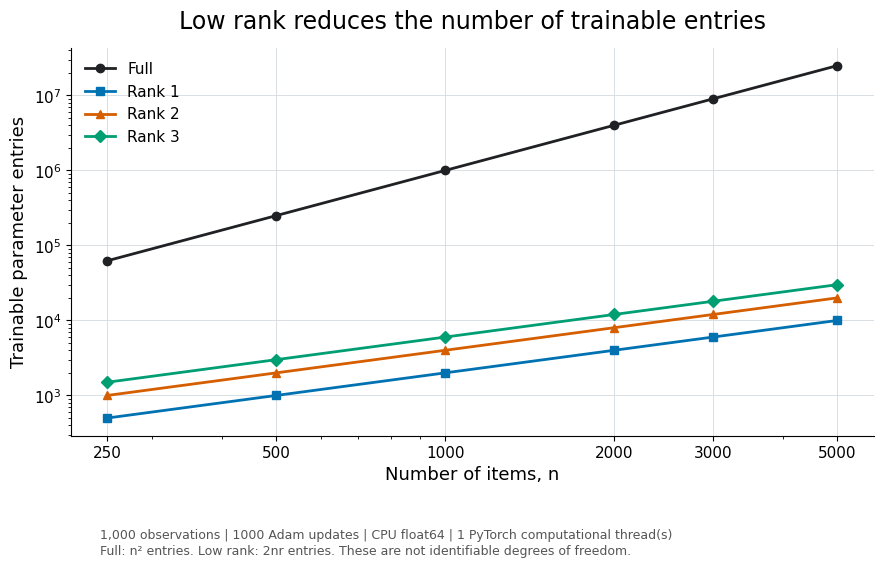

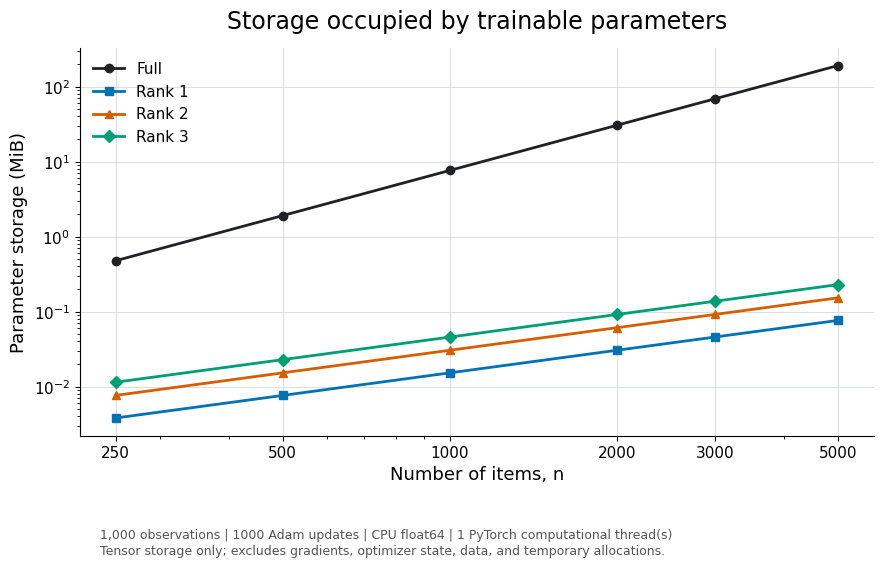

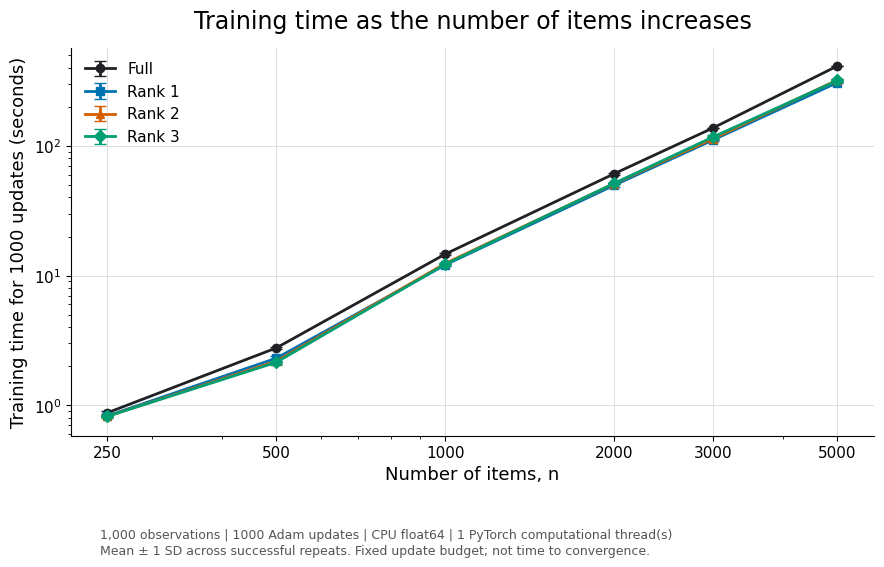

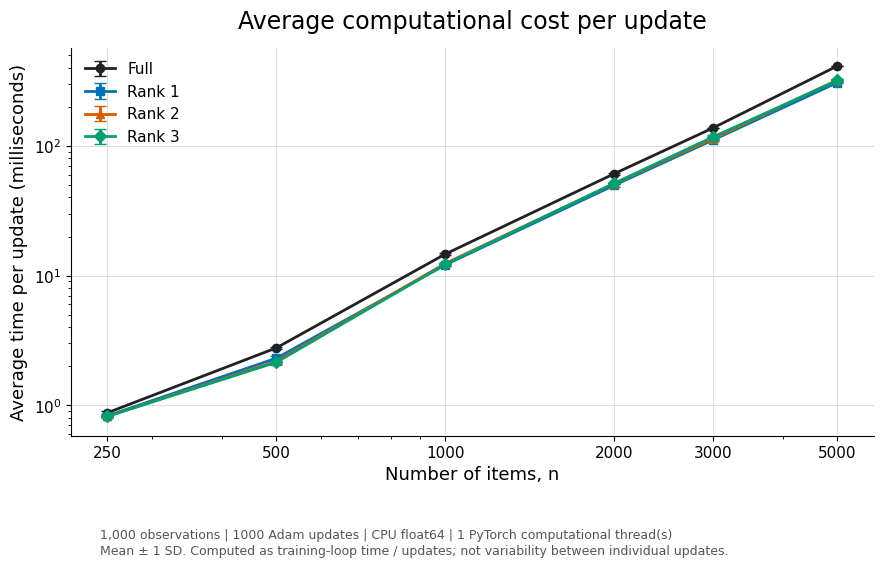

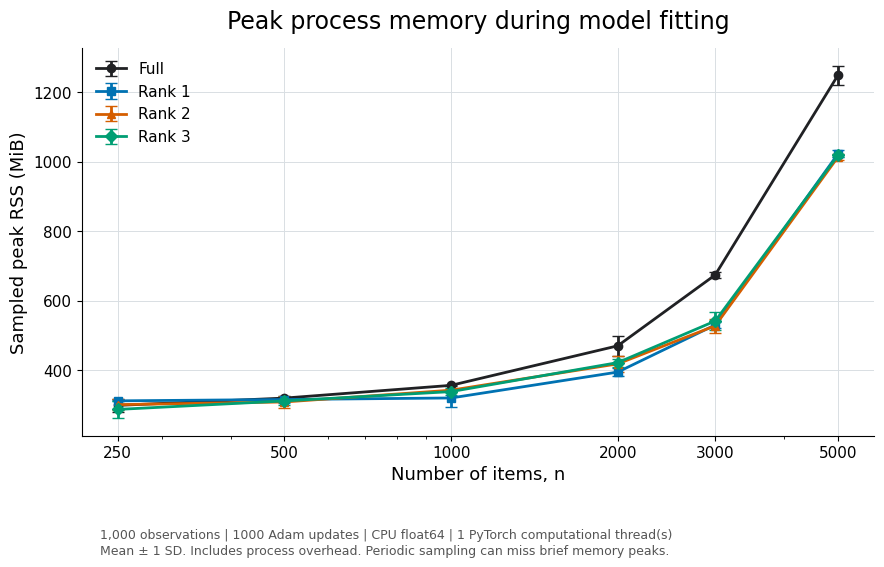

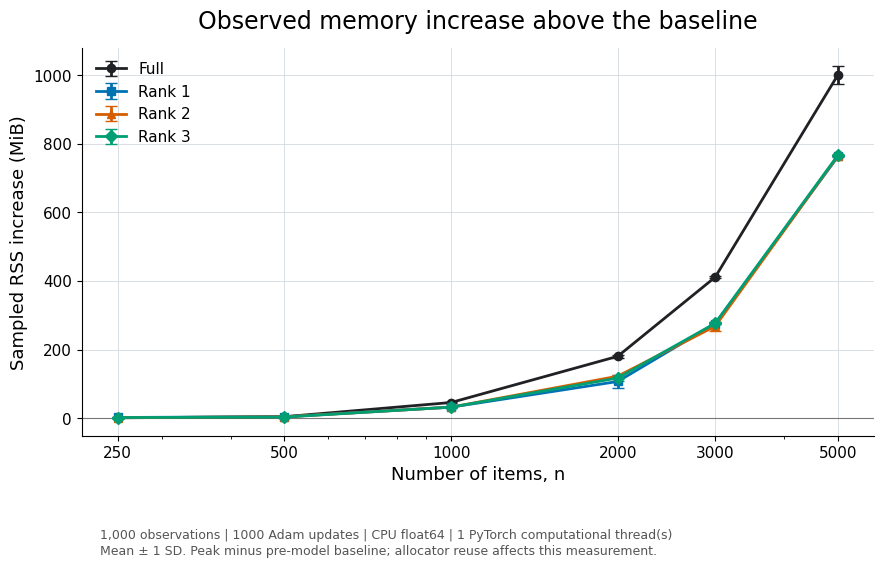

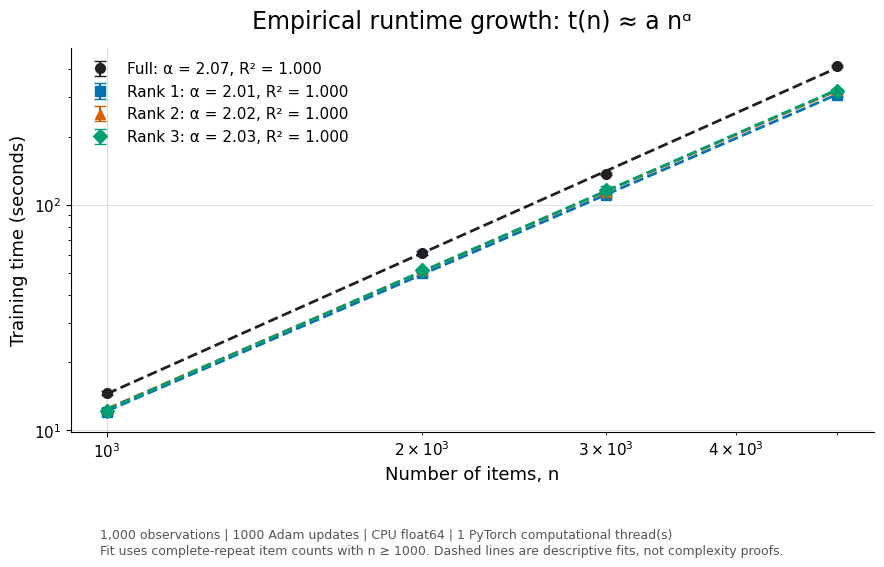

,Model,Items,Runs,Parameters,Time mean (s),Time SD (s),Peak RSS (MiB)
0,Full,250,5,62500,0.876,0.022,299.559
1,Full,500,5,250000,2.770,0.046,320.503
2,Full,1000,5,1000000,14.643,0.320,357.125
3,Full,2000,5,4000000,60.975,1.281,470.828
4,Full,3000,5,9000000,137.423,1.017,674.728
5,Full,5000,5,25000000,413.346,2.486,1249.312
6,Rank 1,250,5,500,0.829,0.020,312.606
7,Rank 1,500,5,1000,2.306,0.105,316.431
8,Rank 1,1000,5,2000,12.089,0.337,320.850
9,Rank 1,2000,5,4000,49.681,1.108,395.331


,Model,Exponent alpha,Log-log R squared,Time multiplier when n doubles,Item counts fitted
0,Full,2.069,1.0,4.197,4
1,Rank 1,2.010,1.0,4.029,4
2,Rank 2,2.021,1.0,4.059,4
3,Rank 3,2.030,1.0,4.083,4


,Figure,PNG
0,01_parameter_count,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
1,02_parameter_storage,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
2,03_training_time,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
3,04_time_per_update,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
4,05_peak_process_memory,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
5,06_memory_increase,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
6,07_empirical_runtime_exponents,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...


All individual figures saved in: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/context_dependent_model/05_full_vs_low_rank_resource_scaling/20261021T202900_245293Z


In [11]:
# Replace the previous Code Cell 4 with this cell.
# Uses successful, runs, CONFIG, and the existing output directories.

summary = (
    successful.groupby(["model", "n"], as_index=False)
    .agg(
        successful_runs=("training_seconds", "size"),
        parameters=("parameters", "first"),
        parameter_mib=("parameter_mib", "first"),
        seconds_mean=("training_seconds", "mean"),
        seconds_std=("training_seconds", "std"),
        ms_per_step_mean=("milliseconds_per_step", "mean"),
        ms_per_step_std=("milliseconds_per_step", "std"),
        peak_rss_mean=("sampled_peak_rss_mib", "mean"),
        peak_rss_std=("sampled_peak_rss_mib", "std"),
        rss_increase_mean=("sampled_rss_increase_mib", "mean"),
        rss_increase_std=("sampled_rss_increase_mib", "std"),
        final_nll_mean=("final_nll", "mean"),
        final_gradient_mean=("final_gradient_norm", "mean"),
    )
    .sort_values(["model", "n"])
)

summary.to_csv(
    TABLE_DIRECTORY / "resource_scaling_summary.csv",
    index=False,
)

# ------------------------------------------------------------
# 1. Estimate empirical runtime exponents.
# Fit log(mean time) = intercept + alpha * log(n).
# Only use item counts with all requested repeats completed.
# ------------------------------------------------------------
FIT_MIN_ITEMS = 1000
fit_rows = []

model_order = ["Full", *[f"Rank {r}" for r in CONFIG["ranks"]]]

for model_name in model_order:
    group = summary.loc[
        summary["model"].eq(model_name)
        & summary["n"].ge(FIT_MIN_ITEMS)
        & summary["successful_runs"].eq(CONFIG["repeats"])
        & summary["seconds_mean"].gt(0)
    ].sort_values("n")

    if len(group) < 3:
        print(
            f"Skipping exponent fit for {model_name}: "
            "need at least 3 item counts with complete repeats."
        )
        continue

    x = np.log(group["n"].to_numpy(dtype=float))
    y = np.log(group["seconds_mean"].to_numpy(dtype=float))

    alpha, intercept = np.polyfit(x, y, deg=1)
    fitted_y = intercept + alpha * x

    residual_sum = np.sum((y - fitted_y) ** 2)
    total_sum = np.sum((y - y.mean()) ** 2)
    r_squared = (
        1 - residual_sum / total_sum
        if total_sum > 0 else np.nan
    )

    fit_rows.append({
        "model": model_name,
        "alpha": alpha,
        "a_seconds": np.exp(intercept),
        "log_log_r_squared": r_squared,
        "doubling_time_multiplier": 2.0 ** alpha,
        "minimum_items": int(group["n"].min()),
        "maximum_items": int(group["n"].max()),
        "item_counts_used": len(group),
        "fit_item_counts": ",".join(map(str, group["n"].tolist())),
    })

exponents = pd.DataFrame(fit_rows)
exponents.to_csv(
    TABLE_DIRECTORY / "runtime_power_law_fits.csv",
    index=False,
)

# Save the fitting convention alongside the results.
(RESULT_DIRECTORY / "power_law_fit_settings.json").write_text(
    json.dumps({
        "fit_minimum_items": FIT_MIN_ITEMS,
        "response": "mean training seconds across successful repeats",
        "method": "ordinary least squares in log-log coordinates",
        "complete_repeats_required": CONFIG["repeats"],
        "interpretation": (
            "Descriptive exponent over the fitted range; "
            "not proof of asymptotic complexity."
        ),
    }, indent=2),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 2. Consistent presentation style.
# ------------------------------------------------------------
palette = ["#202124", "#0072B2", "#D55E00", "#009E73", "#CC79A7"]
markers = ["o", "s", "^", "D", "v"]

colors = {
    name: palette[i % len(palette)]
    for i, name in enumerate(model_order)
}
marker_map = {
    name: markers[i % len(markers)]
    for i, name in enumerate(model_order)
}

style = {
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 17,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
}

experiment_note = (
    f"{CONFIG['observations']:,} observations | "
    f"{CONFIG['steps']} Adam updates | CPU {CONFIG['dtype']} | "
    f"{CONFIG['threads']} PyTorch computational thread(s)"
)

saved_figures = []

def finish_figure(fig, ax, filename, footer):
    ax.grid(True, which="major", color="#D9DEE3", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)

    fig.text(
        0.12, 0.025,
        experiment_note + "\n" + footer,
        fontsize=9,
        color="#555555",
        va="bottom",
    )
    fig.tight_layout(rect=(0, 0.12, 1, 1))

    for extension in ("png", "pdf", "svg"):
        path = FIGURE_DIRECTORY / f"{filename}.{extension}"
        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )

    saved_figures.append({
        "Figure": filename,
        "PNG": str(FIGURE_DIRECTORY / f"{filename}.png"),
    })
    plt.show()
    plt.close(fig)


def draw_scaling_plot(
    y_column,
    error_column,
    title,
    ylabel,
    filename,
    log_y=False,
    footer="",
):
    with plt.rc_context(style):
        fig, ax = plt.subplots(figsize=(9, 5.8))

        for model_name in model_order:
            group = summary.loc[
                summary["model"].eq(model_name)
            ].sort_values("n")

            if group.empty:
                continue

            ax.errorbar(
                group["n"],
                group[y_column],
                yerr=(
                    group[error_column].fillna(0)
                    if error_column else None
                ),
                color=colors[model_name],
                marker=marker_map[model_name],
                linewidth=2,
                markersize=6,
                capsize=4,
                label=model_name,
            )

        ax.set_xscale("log")
        if log_y:
            ax.set_yscale("log")

        ax.set_xticks(CONFIG["items"])
        ax.set_xticklabels([str(n) for n in CONFIG["items"]])
        ax.set_xlabel("Number of items, n")
        ax.set_ylabel(ylabel)
        ax.set_title(title, pad=14)

        if not log_y and y_column == "rss_increase_mean":
            ax.axhline(0, color="#777777", linewidth=0.8)

        finish_figure(fig, ax, filename, footer)


# ------------------------------------------------------------
# 3. Separate plots for presentation and thesis.
# ------------------------------------------------------------
draw_scaling_plot(
    "parameters", None,
    "Low rank reduces the number of trainable entries",
    "Trainable parameter entries",
    "01_parameter_count",
    log_y=True,
    footer=(
        "Full: n² entries. Low rank: 2nr entries. "
        "These are not identifiable degrees of freedom."
    ),
)

draw_scaling_plot(
    "parameter_mib", None,
    "Storage occupied by trainable parameters",
    "Parameter storage (MiB)",
    "02_parameter_storage",
    log_y=True,
    footer=(
        "Tensor storage only; excludes gradients, optimizer state, "
        "data, and temporary allocations."
    ),
)

draw_scaling_plot(
    "seconds_mean", "seconds_std",
    "Training time as the number of items increases",
    f"Training time for {CONFIG['steps']} updates (seconds)",
    "03_training_time",
    log_y=True,
    footer=(
        "Mean ± 1 SD across successful repeats. "
        "Fixed update budget; not time to convergence."
    ),
)

draw_scaling_plot(
    "ms_per_step_mean", "ms_per_step_std",
    "Average computational cost per update",
    "Average time per update (milliseconds)",
    "04_time_per_update",
    log_y=True,
    footer=(
        "Mean ± 1 SD. Computed as training-loop time / updates; "
        "not variability between individual updates."
    ),
)

draw_scaling_plot(
    "peak_rss_mean", "peak_rss_std",
    "Peak process memory during model fitting",
    "Sampled peak RSS (MiB)",
    "05_peak_process_memory",
    footer=(
        "Mean ± 1 SD. Includes process overhead. "
        "Periodic sampling can miss brief memory peaks."
    ),
)

draw_scaling_plot(
    "rss_increase_mean", "rss_increase_std",
    "Observed memory increase above the baseline",
    "Sampled RSS increase (MiB)",
    "06_memory_increase",
    footer=(
        "Mean ± 1 SD. Peak minus pre-model baseline; "
        "allocator reuse affects this measurement."
    ),
)

# ------------------------------------------------------------
# 4. Separate empirical power-law plot.
# ------------------------------------------------------------
if not exponents.empty:
    with plt.rc_context(style):
        fig, ax = plt.subplots(figsize=(9, 5.8))

        for row in exponents.itertuples(index=False):
            included_n = [
                int(value) for value in row.fit_item_counts.split(",")
            ]
            group = summary.loc[
                summary["model"].eq(row.model)
                & summary["n"].isin(included_n)
            ].sort_values("n")

            color = colors[row.model]

            ax.errorbar(
                group["n"],
                group["seconds_mean"],
                yerr=group["seconds_std"].fillna(0),
                fmt=marker_map[row.model],
                color=color,
                markersize=7,
                capsize=4,
                label=(
                    f"{row.model}: α = {row.alpha:.2f}, "
                    f"R² = {row.log_log_r_squared:.3f}"
                ),
            )

            # Only show the fit within the observed range.
            n_line = np.geomspace(
                row.minimum_items, row.maximum_items, 100
            )
            ax.plot(
                n_line,
                row.a_seconds * n_line ** row.alpha,
                color=color,
                linestyle="--",
                linewidth=2,
            )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Number of items, n")
        ax.set_ylabel("Training time (seconds)")
        ax.set_title("Empirical runtime growth: t(n) ≈ a nᵅ", pad=14)

        finish_figure(
            fig, ax, "07_empirical_runtime_exponents",
            (
                f"Fit uses complete-repeat item counts with n ≥ {FIT_MIN_ITEMS}. "
                "Dashed lines are descriptive fits, not complexity proofs."
            ),
        )

# ------------------------------------------------------------
# 5. Compact tables for Overleaf and inspection.
# ------------------------------------------------------------
thesis_table = summary[[
    "model", "n", "successful_runs", "parameters",
    "seconds_mean", "seconds_std", "peak_rss_mean",
]].rename(columns={
    "model": "Model",
    "n": "Items",
    "successful_runs": "Runs",
    "parameters": "Parameters",
    "seconds_mean": "Time mean (s)",
    "seconds_std": "Time SD (s)",
    "peak_rss_mean": "Peak RSS (MiB)",
})

(TABLE_DIRECTORY / "resource_scaling_summary.tex").write_text(
    thesis_table.to_latex(index=False, float_format="%.3f"),
    encoding="utf-8",
)

display(thesis_table.round(3))

if not exponents.empty:
    exponent_table = exponents[[
        "model", "alpha", "log_log_r_squared",
        "doubling_time_multiplier", "item_counts_used",
    ]].rename(columns={
        "model": "Model",
        "alpha": "Exponent alpha",
        "log_log_r_squared": "Log-log R squared",
        "doubling_time_multiplier": "Time multiplier when n doubles",
        "item_counts_used": "Item counts fitted",
    })

    display(exponent_table.round(3))

    (TABLE_DIRECTORY / "runtime_power_law_fits.tex").write_text(
        exponent_table.to_latex(index=False, float_format="%.3f"),
        encoding="utf-8",
    )

failures = runs.loc[~runs["status"].eq("ok")]
if not failures.empty:
    print("Failed/timed-out runs were excluded from plotted averages:")
    display(failures[["n", "model", "repeat", "status", "error"]])

incomplete = summary.loc[
    summary["successful_runs"] < CONFIG["repeats"],
    ["model", "n", "successful_runs"],
]
if not incomplete.empty:
    print("Incomplete groups are plotted but excluded from exponent fits:")
    display(incomplete)

display(pd.DataFrame(saved_figures))
print("All individual figures saved in:", FIGURE_DIRECTORY)